# 08 - WoE / IV Calculation Check, Interpretation Review and Final Selection

**Project:** German Credit Risk
**Inputs:** the raw data `data/german_credit_data.csv` and the saved outputs of notebook 05 in `data/processed/`
**Author:** Divya Akbari

**Goal of this notebook**
1. **Validate the WoE / IV calculations**: rebuild everything from the raw data and check the saved results step by step.
2. **Review the feature-level interpretations**: test every statement made about each feature against the data.
3. **Finalise the feature selection** and save the final, model-ready files.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.proportion import proportion_confint, proportions_ztest
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import StratifiedShuffleSplit, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve

pd.set_option('display.width', 150)
pd.set_option('display.max_colwidth', None)

raw = pd.read_csv('data/german_credit_data.csv').drop(columns=['Unnamed: 0'])
saved_fe = pd.read_csv('data/processed/german_credit_engineered.csv')
saved_tables = pd.read_csv('data/processed/woe_iv_tables.csv')
saved_woe = pd.read_csv('data/processed/german_credit_woe.csv')
print(raw.shape, saved_fe.shape, saved_tables.shape, saved_woe.shape)

(1000, 10) (1000, 26) (37, 9) (1000, 9)


## Part A - Validate the WoE / IV calculations

### A1. Rebuild the engineered features from the raw data
Every binned feature is created again from the raw file, using the rules written in notebook 05, and compared with the saved dataset.

In [2]:
fe = raw.copy()
fe['bad'] = (fe['Risk'] == 'bad').astype(int)
fe['checking_status'] = fe['Checking account'].fillna('no account')
fe['saving_status'] = fe['Saving accounts'].fillna('no record').replace({'quite rich': 'quite rich/rich', 'rich': 'quite rich/rich'})
fe['low_balance_profile'] = ((fe['checking_status'] == 'little') & fe['saving_status'].isin(['little', 'no record'])).astype(int)
fe['monthly_payment'] = (fe['Credit amount'] / fe['Duration']).round(2)
fe['duration_bin'] = pd.cut(fe['Duration'], [0, 11, 23, 35, 100], labels=['up to 11', '12-23', '24-35', '36+']).astype(str)
fe['age_bin'] = pd.cut(fe['Age'], [18, 25, 33, 100], labels=['25 or under', '26-33', '34+']).astype(str)
fe['credit_bin'] = pd.cut(fe['Credit amount'], [0, 1500, 4000, 7500, 1e9], labels=['up to 1,500', '1,501-4,000', '4,001-7,500', 'over 7,500']).astype(str)
fe['payment_bin'] = pd.cut(fe['monthly_payment'], [0, 80, 150, 1e9], labels=['up to 80', '81-150', 'over 150']).astype(str)
fe['purpose_group'] = fe['Purpose'].replace({'education': 'education/other', 'repairs': 'education/other',
                                             'domestic appliances': 'education/other', 'vacation/others': 'education/other'})
fe['job_group'] = fe['Job'].map({0: 'unskilled', 1: 'unskilled', 2: 'skilled', 3: 'highly skilled'})
fe['housing'] = fe['Housing']
fe['sex'] = fe['Sex']

rebuilt = ['bad', 'checking_status', 'saving_status', 'low_balance_profile', 'monthly_payment', 'duration_bin', 'age_bin',
           'credit_bin', 'payment_bin', 'purpose_group', 'job_group']
rebuild_check = pd.DataFrame({'Column': rebuilt,
                              'Identical to saved file': [bool((fe[c].astype(str).values == saved_fe[c].astype(str).values).all()) for c in rebuilt]})
rebuild_check

,Column,Identical to saved file
0,bad,True
1,checking_status,True
2,saving_status,True
3,low_balance_profile,True
4,monthly_payment,True
5,duration_bin,True
6,age_bin,True
7,credit_bin,True
8,payment_bin,True
9,purpose_group,True


### A2. Worked example: WoE and IV of Checking account status, step by step

| Step | Formula |
|---|---|
| Share of good customers in the band | % good = good in band / all good customers (700) |
| Share of bad customers in the band | % bad = bad in band / all bad customers (300) |
| Weight of Evidence | WoE = ln(% good / % bad) |
| IV part | (% good - % bad) x WoE |
| Information Value | IV = sum of the IV parts |

0.5 is added to each count before dividing (a standard safeguard so that a band with no good or no bad customers cannot cause a division by zero).

In [3]:
TOTAL_GOOD = (fe['bad'] == 0).sum()
TOTAL_BAD = fe['bad'].sum()
print('Good customers:', TOTAL_GOOD, ' Bad customers:', TOTAL_BAD)

def woe_steps(data, feature):
    g = data.groupby(feature)['bad'].agg(Customers='size', Bad='sum')
    g['Good'] = g['Customers'] - g['Bad']
    g['% good'] = (g['Good'] + 0.5) / (data['bad'] == 0).sum()
    g['% bad'] = (g['Bad'] + 0.5) / data['bad'].sum()
    g['WoE'] = np.log(g['% good'] / g['% bad'])
    g['IV part'] = (g['% good'] - g['% bad']) * g['WoE']
    return g[['Customers', 'Good', 'Bad', '% good', '% bad', 'WoE', 'IV part']]

example = woe_steps(fe, 'checking_status').loc[['no account', 'rich', 'moderate', 'little']]
print('IV of Checking account status =', round(example['IV part'].sum(), 4))
example.round(4)

Good customers: 700  Bad customers: 300
IV of Checking account status = 0.6621


,Customers,Good,Bad,% good,% bad,WoE,IV part
checking_status,,,,,,,
no account,394,348,46,0.4979,0.1550,1.1669,0.4001
rich,63,49,14,0.0707,0.0483,0.3805,0.0085
moderate,269,164,105,0.2350,0.3517,-0.4031,0.0470
little,274,139,135,0.1993,0.4517,-0.8182,0.2065


**Reading the example:** the "no account" band holds 49.7% of all good customers but only 15.5% of all bad customers,
so WoE = ln(0.497 / 0.155) = +1.17 (much safer than average). The "little" band holds 19.9% of good and 45.0% of bad customers,
so WoE = ln(0.199 / 0.450) = -0.82 (much riskier than average).

### A3. Independent recalculation of every feature
All WoE values and IVs are recalculated with the step-by-step method above and compared with the saved table from notebook 05.

In [4]:
features = ['checking_status', 'low_balance_profile', 'duration_bin', 'saving_status', 'credit_bin', 'age_bin',
            'housing', 'payment_bin', 'purpose_group', 'sex', 'job_group']
names = {'checking_status': 'Checking account status', 'low_balance_profile': 'Low balance profile', 'duration_bin': 'Duration',
         'saving_status': 'Saving account status', 'credit_bin': 'Credit amount', 'age_bin': 'Age', 'housing': 'Housing',
         'payment_bin': 'Monthly payment', 'purpose_group': 'Purpose group', 'sex': 'Sex', 'job_group': 'Job group'}

rows = []
for f in features:
    mine = woe_steps(fe, f)
    mine.index = mine.index.astype(str)
    theirs = saved_tables[saved_tables['Feature'] == f].set_index('Band')
    theirs.index = theirs.index.astype(str)
    rows.append([names[f], len(mine), round(mine['IV part'].sum(), 4), round(theirs['IV part'].sum(), 4),
                 round((mine['WoE'] - theirs['WoE'].reindex(mine.index)).abs().max(), 4),
                 int((mine['Customers'] == theirs['Customers'].reindex(mine.index)).all())])
recalc = pd.DataFrame(rows, columns=['Feature', 'Bands', 'IV recalculated', 'IV saved', 'Largest WoE difference', 'Counts identical'])
recalc['Match'] = np.where((recalc['Largest WoE difference'] < 0.001) & (recalc['Counts identical'] == 1), 'Yes', 'No')
recalc

,Feature,Bands,IV recalculated,IV saved,Largest WoE difference,Counts identical,Match
0,Checking account status,4,0.6621,0.6621,0.0005,1,Yes
1,Low balance profile,2,0.3267,0.3266,0.0004,1,Yes
2,Duration,4,0.2301,0.2301,0.0005,1,Yes
3,Saving account status,4,0.1885,0.1885,0.0004,1,Yes
4,Credit amount,4,0.1422,0.1423,0.0005,1,Yes
5,Age,3,0.0929,0.0929,0.0005,1,Yes
6,Housing,3,0.0841,0.0842,0.0004,1,Yes
7,Monthly payment,3,0.0771,0.0771,0.0003,1,Yes
8,Purpose group,5,0.0665,0.0666,0.0005,1,Yes
9,Sex,2,0.0267,0.0267,0.0004,1,Yes


The only differences come from the saved table being rounded to 3 decimals.

### A4. Mathematical properties
A correct WoE / IV calculation must have these properties for every feature:
1. The % good and % bad columns each add up to 1 (before the 0.5 safeguard).
2. Every IV part is zero or positive, because (% good - % bad) and WoE always have the same sign.
3. A band with a bad rate **below** the overall 30% has a **positive** WoE, and a band above 30% has a negative WoE.
4. Ranking the bands by WoE gives exactly the reverse of ranking them by bad rate.
5. The 0.5 safeguard changes WoE only slightly.

In [5]:
rows = []
for f in features:
    s = woe_steps(fe, f)
    good_sum = (s['Good'] / TOTAL_GOOD).sum()
    bad_sum = (s['Bad'] / TOTAL_BAD).sum()
    bad_rate = s['Bad'] / s['Customers']
    raw_woe = np.log((s['Good'] / TOTAL_GOOD) / (s['Bad'] / TOTAL_BAD))
    rows.append([names[f], round(good_sum, 6), round(bad_sum, 6), bool((s['IV part'] >= 0).all()),
                 bool(((bad_rate < 0.30) == (s['WoE'] > 0)).all()),
                 round(stats.spearmanr(bad_rate, s['WoE'])[0], 3), round((s['WoE'] - raw_woe).abs().max(), 4)])
properties = pd.DataFrame(rows, columns=['Feature', 'Sum % good', 'Sum % bad', 'IV parts >= 0', 'WoE sign matches bad rate',
                                         'Rank correlation (bad rate, WoE)', 'Largest effect of 0.5 safeguard'])
properties

,Feature,Sum % good,Sum % bad,IV parts >= 0,WoE sign matches bad rate,"Rank correlation (bad rate, WoE)",Largest effect of 0.5 safeguard
0,Checking account status,1.0,1.0,True,True,-1.0,0.0249
1,Low balance profile,1.0,1.0,True,True,-1.0,0.0020
2,Duration,1.0,1.0,True,True,-1.0,0.0151
3,Saving account status,1.0,1.0,True,True,-1.0,0.0237
4,Credit amount,1.0,1.0,True,True,-1.0,0.0034
5,Age,1.0,1.0,True,True,-1.0,0.0028
6,Housing,1.0,1.0,True,True,-1.0,0.0035
7,Monthly payment,1.0,1.0,True,True,-1.0,0.0030
8,Purpose group,1.0,1.0,True,True,-1.0,0.0067
9,Sex,1.0,1.0,True,True,-1.0,0.0021


### A5. The saved WoE dataset
Each WoE column in `german_credit_woe.csv` must equal the customer's band mapped to that band's WoE.

In [6]:
rows = []
for col in [c for c in saved_woe.columns if c != 'bad']:
    f = col.replace('woe_', '')
    mapping = woe_steps(fe, f)['WoE'].round(3)
    mapping.index = mapping.index.astype(str)
    expected = fe[f].astype(str).map(mapping)
    rows.append([names[f], col, round((expected - saved_woe[col]).abs().max(), 6)])
woe_dataset_check = pd.DataFrame(rows, columns=['Feature', 'Column', 'Largest difference'])
woe_dataset_check['Match'] = np.where(woe_dataset_check['Largest difference'] < 1e-6, 'Yes', 'No')
print('Target column identical:', (saved_woe['bad'] == fe['bad']).all())
woe_dataset_check

Target column identical: True


,Feature,Column,Largest difference,Match
0,Checking account status,woe_checking_status,0.0,Yes
1,Duration,woe_duration_bin,0.0,Yes
2,Saving account status,woe_saving_status,0.0,Yes
3,Credit amount,woe_credit_bin,0.0,Yes
4,Age,woe_age_bin,0.0,Yes
5,Housing,woe_housing,0.0,Yes
6,Monthly payment,woe_payment_bin,0.0,Yes
7,Purpose group,woe_purpose_group,0.0,Yes


## Part B - Review of the feature-level interpretations

Each statement made about a feature in the earlier reports is tested against the data.
- **95% confidence intervals** (Wilson method) show how precisely each band's bad rate is known.
- **Pairwise tests** (two-proportion z-test) check whether neighbouring bands really differ.
- **Trend tests** (Cochran-Armitage) check whether risk moves steadily across ordered bands.

In [7]:
order = {
    'checking_status': ['no account', 'rich', 'moderate', 'little'], 'duration_bin': ['up to 11', '12-23', '24-35', '36+'],
    'saving_status': ['no record', 'quite rich/rich', 'moderate', 'little'], 'credit_bin': ['up to 1,500', '1,501-4,000', '4,001-7,500', 'over 7,500'],
    'payment_bin': ['up to 80', '81-150', 'over 150'], 'age_bin': ['25 or under', '26-33', '34+'], 'housing': ['own', 'rent', 'free'],
    'purpose_group': ['radio/TV', 'car', 'furniture/equipment', 'business', 'education/other'], 'sex': ['male', 'female'],
    'job_group': ['unskilled', 'skilled', 'highly skilled'],
}

def band_rates(f):
    g = fe.groupby(f)['bad'].agg(Customers='size', Bad='sum').loc[order[f]]
    low, high = proportion_confint(g['Bad'], g['Customers'], method='wilson')
    g['Bad rate (%)'] = (g['Bad'] / g['Customers'] * 100).round(1)
    g['95% CI'] = [f'{l*100:.1f} to {h*100:.1f}' for l, h in zip(low, high)]
    return g

def compare(f, a, b):
    g = fe.groupby(f)['bad'].agg(n='size', b='sum')
    return proportions_ztest([g.loc[a, 'b'], g.loc[b, 'b']], [g.loc[a, 'n'], g.loc[b, 'n']])[1]

def trend(f, levels):
    d = fe[fe[f].isin(levels)]
    score = d[f].map({k: i for i, k in enumerate(levels)})
    y = d['bad']
    z = ((score - score.mean()) * y).sum() / np.sqrt(y.mean() * (1 - y.mean()) * ((score - score.mean()) ** 2).sum())
    return 2 * stats.norm.sf(abs(z))

for f in order:
    print(names[f])
    print(band_rates(f))
    print()

Checking account status
                 Customers  Bad  Bad rate (%)        95% CI
checking_status                                            
no account             394   46          11.7   8.9 to 15.2
rich                    63   14          22.2  13.7 to 33.9
moderate               269  105          39.0  33.4 to 45.0
little                 274  135          49.3  43.4 to 55.2

Duration
              Customers  Bad  Bad rate (%)        95% CI
duration_bin                                            
up to 11            180   27          15.0  10.5 to 20.9
12-23               406  115          28.3  24.2 to 32.9
24-35               244   76          31.1  25.7 to 37.2
36+                 170   82          48.2  40.8 to 55.7

Saving account status
                 Customers  Bad  Bad rate (%)        95% CI
saving_status                                              
no record              183   32          17.5  12.7 to 23.6
quite rich/rich        111   17          15.3   9.8 to 23.2
m

In [8]:
tests = [
    ('Checking account status', 'Risk falls as the balance rises (little > moderate > rich)', trend('checking_status', ['little', 'moderate', 'rich']), 'trend'),
    ('Checking account status', '"No account" is safer than "rich"', compare('checking_status', 'no account', 'rich'), 'pair'),
    ('Duration', 'Risk rises with loan length', trend('duration_bin', order['duration_bin']), 'trend'),
    ('Duration', 'Up to 11 months is safer than 12-23', compare('duration_bin', 'up to 11', '12-23'), 'pair'),
    ('Duration', '12-23 and 24-35 months differ', compare('duration_bin', '12-23', '24-35'), 'pair'),
    ('Duration', '36+ months is riskier than 24-35', compare('duration_bin', '24-35', '36+'), 'pair'),
    ('Saving account status', 'Risk falls as savings rise', trend('saving_status', ['little', 'moderate', 'quite rich/rich']), 'trend'),
    ('Saving account status', '"Little" and "moderate" savings differ', compare('saving_status', 'little', 'moderate'), 'pair'),
    ('Saving account status', '"Quite rich/rich" is safer than "moderate"', compare('saving_status', 'moderate', 'quite rich/rich'), 'pair'),
    ('Credit amount', 'The smallest loans are riskier than mid-sized loans (U-shape)', compare('credit_bin', 'up to 1,500', '1,501-4,000'), 'pair'),
    ('Credit amount', 'Loans of 4,001-7,500 are riskier than 1,501-4,000', compare('credit_bin', '1,501-4,000', '4,001-7,500'), 'pair'),
    ('Credit amount', 'Loans over 7,500 are riskier than 4,001-7,500', compare('credit_bin', '4,001-7,500', 'over 7,500'), 'pair'),
    ('Monthly payment', 'Risk falls as the monthly payment rises', trend('payment_bin', order['payment_bin']), 'trend'),
    ('Monthly payment', 'Up to 80 DM is riskier than 81-150', compare('payment_bin', 'up to 80', '81-150'), 'pair'),
    ('Monthly payment', '81-150 and over 150 DM differ', compare('payment_bin', '81-150', 'over 150'), 'pair'),
    ('Age', 'Risk falls with age', trend('age_bin', order['age_bin']), 'trend'),
    ('Age', '25 or under is riskier than 26-33', compare('age_bin', '25 or under', '26-33'), 'pair'),
    ('Age', '26-33 is riskier than 34+', compare('age_bin', '26-33', '34+'), 'pair'),
    ('Housing', 'Owners are safer than renters', compare('housing', 'own', 'rent'), 'pair'),
    ('Housing', 'Renters and free housing differ', compare('housing', 'rent', 'free'), 'pair'),
    ('Purpose group', 'Radio/TV is safer than car loans', compare('purpose_group', 'radio/TV', 'car'), 'pair'),
    ('Purpose group', 'Car and education/other differ', compare('purpose_group', 'car', 'education/other'), 'pair'),
    ('Purpose group', 'Car and business differ', compare('purpose_group', 'car', 'business'), 'pair'),
    ('Sex', 'Women are riskier than men', compare('sex', 'male', 'female'), 'pair'),
    ('Job group', 'Job levels differ in risk', stats.chi2_contingency(pd.crosstab(fe['job_group'], fe['bad']))[1], 'chi2'),
]
claims = pd.DataFrame(tests, columns=['Feature', 'Statement tested', 'p-value', 'Test'])
claims['p-value'] = claims['p-value'].round(4)
claims['Supported'] = np.where(claims['p-value'] < 0.05, 'Yes', 'No')
claims

,Feature,Statement tested,p-value,Test,Supported
0,Checking account status,Risk falls as the balance rises (little > moderate > rich),0.0000,trend,Yes
1,Checking account status,"""No account"" is safer than ""rich""",0.0214,pair,Yes
2,Duration,Risk rises with loan length,0.0000,trend,Yes
3,Duration,Up to 11 months is safer than 12-23,0.0005,pair,Yes
4,Duration,12-23 and 24-35 months differ,0.4443,pair,No
5,Duration,36+ months is riskier than 24-35,0.0004,pair,Yes
6,Saving account status,Risk falls as savings rise,0.0001,trend,Yes
7,Saving account status,"""Little"" and ""moderate"" savings differ",0.5597,pair,No
8,Saving account status,"""Quite rich/rich"" is safer than ""moderate""",0.0024,pair,Yes
9,Credit amount,The smallest loans are riskier than mid-sized loans (U-shape),0.1334,pair,No


In [9]:
sex_age = sm.Logit(fe['bad'], sm.add_constant(pd.get_dummies(fe[['sex', 'age_bin']], drop_first=True).astype(float))).fit(disp=0)
print('Women vs men after allowing for age: p =', round(sex_age.pvalues['sex_male'], 3))
print('Average age: women', round(fe.loc[fe.sex == 'female', 'Age'].mean(), 1), ', men', round(fe.loc[fe.sex == 'male', 'Age'].mean(), 1))

Women vs men after allowing for age: p = 0.215
Average age: women 32.8 , men 36.8


### B1. Verdict on each interpretation

| Feature | Earlier interpretation | Verdict | Corrected interpretation |
|---|---|---|---|
| Checking account status | "No account" safest, "little" riskiest; risk falls as balance rises | **Confirmed** | Unchanged. All neighbouring bands differ significantly. Why a missing account is safer is not documented in the data, so "banks elsewhere" is a likely explanation, not a fact. |
| Duration | Risk rises steadily with loan length | **Partly confirmed** | Risk rises with length, but in two steps: at 12 months and at 36 months. Loans of 12-23 and 24-35 months have similar risk. |
| Saving account status | Risk falls as savings rise | **Partly confirmed** | Works as a threshold: "little" and "moderate" savings are equally risky; "quite rich/rich" and "no record" are much safer. |
| Credit amount | U-shaped: smallest loans riskier than mid-sized | **Not confirmed** | The small-loan increase is not significant (p = 0.13). Risk is roughly flat up to 4,000 DM and then rises sharply. |
| Monthly payment | Risk falls as payments rise | **Partly confirmed** | Works as a threshold: payments of 80 DM or less are riskier; above 80 DM risk is similar. |
| Age | Risk falls with age | **Confirmed** | Unchanged. Every step is significant. |
| Housing | Owners safer than renters and free housing | **Confirmed** | Renters and free housing have the same risk, so the feature is really "owns home or not". |
| Purpose group | Radio/TV safest; education/other riskiest | **Partly confirmed** | Only radio/TV stands out. The other purposes do not differ from each other, which explains the unstable pattern found earlier. |
| Sex | Women riskier than men | **Weak** | Significant on its own (p = 0.017) but not after allowing for age (p = 0.22). Excluded as a protected characteristic. |
| Job group | No relationship with risk | **Confirmed** | Unchanged. |

## Part C - Final feature selection

The review shows that **Purpose group** and **Housing** are really two-group features. Simplifying them may fix the
instability found in notebook 07. Both versions are compared over 100 random 70/30 splits.

In [10]:
fe['purpose_type'] = np.where(fe['purpose_group'] == 'radio/TV', 'radio/TV', 'other')
fe['home_owner'] = np.where(fe['housing'] == 'own', 'own', 'rent/free')
names.update({'purpose_type': 'Purpose (radio/TV vs other)', 'home_owner': 'Housing (own vs rent/free)'})

def woe_map(data, f):
    return woe_steps(data, f)['WoE']

core = ['checking_status', 'duration_bin', 'saving_status', 'credit_bin', 'age_bin', 'payment_bin']
feature_sets = {
    'Previous 8 (housing 3 bands, purpose 5 bands)': core + ['housing', 'purpose_group'],
    'Refined 8 (housing 2 bands, purpose 2 bands)': core + ['home_owner', 'purpose_type'],
    '7 features (without purpose)': core + ['housing'],
}
auc = {k: [] for k in feature_sets}
direction = {'purpose_group': [], 'purpose_type': [], 'housing': [], 'home_owner': []}
for train_idx, test_idx in StratifiedShuffleSplit(n_splits=100, test_size=0.3, random_state=11).split(fe, fe['bad']):
    tr, te = fe.iloc[train_idx], fe.iloc[test_idx]
    for k, feats in feature_sets.items():
        X_tr = pd.DataFrame({f: tr[f].map(woe_map(tr, f)) for f in feats})
        X_te = pd.DataFrame({f: te[f].map(woe_map(tr, f)).fillna(0) for f in feats})
        auc[k].append(roc_auc_score(te['bad'], LogisticRegression(max_iter=1000).fit(X_tr, tr['bad']).predict_proba(X_te)[:, 1]))
    for f in direction:
        w_tr, w_te = woe_map(tr, f), woe_map(te, f).reindex(woe_map(tr, f).index)
        direction[f].append((np.sign(w_tr) == np.sign(w_te)).mean())   # share of bands whose WoE keeps its sign

base = np.array(auc['Previous 8 (housing 3 bands, purpose 5 bands)'])
refinement = pd.DataFrame({
    'Feature set': list(feature_sets),
    'Mean hold-out ROC-AUC': [round(np.mean(auc[k]), 4) for k in feature_sets],
    'Change vs previous': [round(np.mean(np.array(auc[k]) - base), 4) for k in feature_sets],
    'Better than previous (% of splits)': [round(np.mean(np.array(auc[k]) > base) * 100) for k in feature_sets],
})
stability = pd.DataFrame({'Feature': [names[f] for f in direction],
                          'Bands': [fe[f].nunique() for f in direction],
                          'IV': [round(woe_steps(fe, f)['IV part'].sum(), 3) for f in direction],
                          'Bands keeping their WoE sign (%)': [round(np.mean(direction[f]) * 100, 1) for f in direction]})
print(stability)
refinement

                       Feature  Bands     IV  Bands keeping their WoE sign (%)
0                Purpose group      5  0.066                              78.0
1  Purpose (radio/TV vs other)      2  0.057                              99.0
2                      Housing      3  0.084                              98.0
3   Housing (own vs rent/free)      2  0.083                             100.0


,Feature set,Mean hold-out ROC-AUC,Change vs previous,Better than previous (% of splits)
0,"Previous 8 (housing 3 bands, purpose 5 bands)",0.7725,0.0000,0
1,"Refined 8 (housing 2 bands, purpose 2 bands)",0.7745,0.0019,71
2,7 features (without purpose),0.7715,-0.0011,30


The two-band versions keep almost all of the information (IV changes little), their risk direction is stable in practically every
split, and the refined set gives a slightly **higher** hold-out ROC-AUC than the previous one. The refined bands are therefore adopted.

### C1. The final feature set

In [11]:
final = ['checking_status', 'duration_bin', 'saving_status', 'credit_bin', 'payment_bin', 'age_bin', 'home_owner', 'purpose_type']
tier = {'checking_status': 'Tier 1 - Critical', 'duration_bin': 'Tier 2 - Important', 'saving_status': 'Tier 2 - Important',
        'credit_bin': 'Tier 2 - Important', 'payment_bin': 'Tier 2 - Important', 'age_bin': 'Tier 3 - Supporting',
        'home_owner': 'Tier 3 - Supporting', 'purpose_type': 'Tier 3 - Supporting'}

X = pd.DataFrame({f: fe[f].map(woe_map(fe, f)) for f in final})
X_const = sm.add_constant(X)
logit = sm.Logit(fe['bad'], X_const).fit(disp=0)
final_table = pd.DataFrame({
    'Column': final, 'Feature': [names[f] for f in final], 'Tier': [tier[f] for f in final],
    'Bands': [fe[f].nunique() for f in final], 'IV': [round(woe_steps(fe, f)['IV part'].sum(), 3) for f in final],
    'VIF': [round(variance_inflation_factor(X_const.values, i + 1), 2) for i in range(len(final))],
    'Coefficient': logit.params.iloc[1:].round(3).values, 'p-value': logit.pvalues.iloc[1:].round(4).values,
})
final_table

,Column,Feature,Tier,Bands,IV,VIF,Coefficient,p-value
0,checking_status,Checking account status,Tier 1 - Critical,4,0.662,1.11,-0.849,0.0000
1,duration_bin,Duration,Tier 2 - Important,4,0.230,1.23,-0.627,0.0005
2,saving_status,Saving account status,Tier 2 - Important,4,0.189,1.07,-0.745,0.0001
3,credit_bin,Credit amount,Tier 2 - Important,4,0.142,1.31,-0.999,0.0000
4,payment_bin,Monthly payment,Tier 2 - Important,3,0.077,1.14,-1.338,0.0000
5,age_bin,Age,Tier 3 - Supporting,3,0.093,1.05,-0.773,0.0027
6,home_owner,Housing (own vs rent/free),Tier 3 - Supporting,2,0.083,1.05,-0.609,0.0259
7,purpose_type,Purpose (radio/TV vs other),Tier 3 - Supporting,2,0.057,1.07,-0.773,0.0264


In [12]:
train, test = train_test_split(fe, test_size=0.3, stratify=fe['bad'], random_state=2026)
X_tr = pd.DataFrame({f: train[f].map(woe_map(train, f)) for f in final})
X_te = pd.DataFrame({f: test[f].map(woe_map(train, f)).fillna(0) for f in final})
model = LogisticRegression(max_iter=1000).fit(X_tr, train['bad'])
p_tr, p_te = model.predict_proba(X_tr)[:, 1], model.predict_proba(X_te)[:, 1]
fpr, tpr, _ = roc_curve(test['bad'], p_te)
performance = pd.DataFrame({'Sample': ['Training (70%)', 'Hold-out (30%)'], 'Customers': [len(train), len(test)],
                            'ROC-AUC': [round(roc_auc_score(train['bad'], p_tr), 3), round(roc_auc_score(test['bad'], p_te), 3)]})
performance['Gini'] = (2 * performance['ROC-AUC'] - 1).round(3)
ks = round((tpr - fpr).max(), 3)
print('KS on hold-out sample:', ks)
print('Mean hold-out ROC-AUC over 100 splits:', refinement.loc[1, 'Mean hold-out ROC-AUC'])
performance

KS on hold-out sample: 0.49
Mean hold-out ROC-AUC over 100 splits: 0.7745


,Sample,Customers,ROC-AUC,Gini
0,Training (70%),700,0.802,0.604
1,Hold-out (30%),300,0.753,0.506


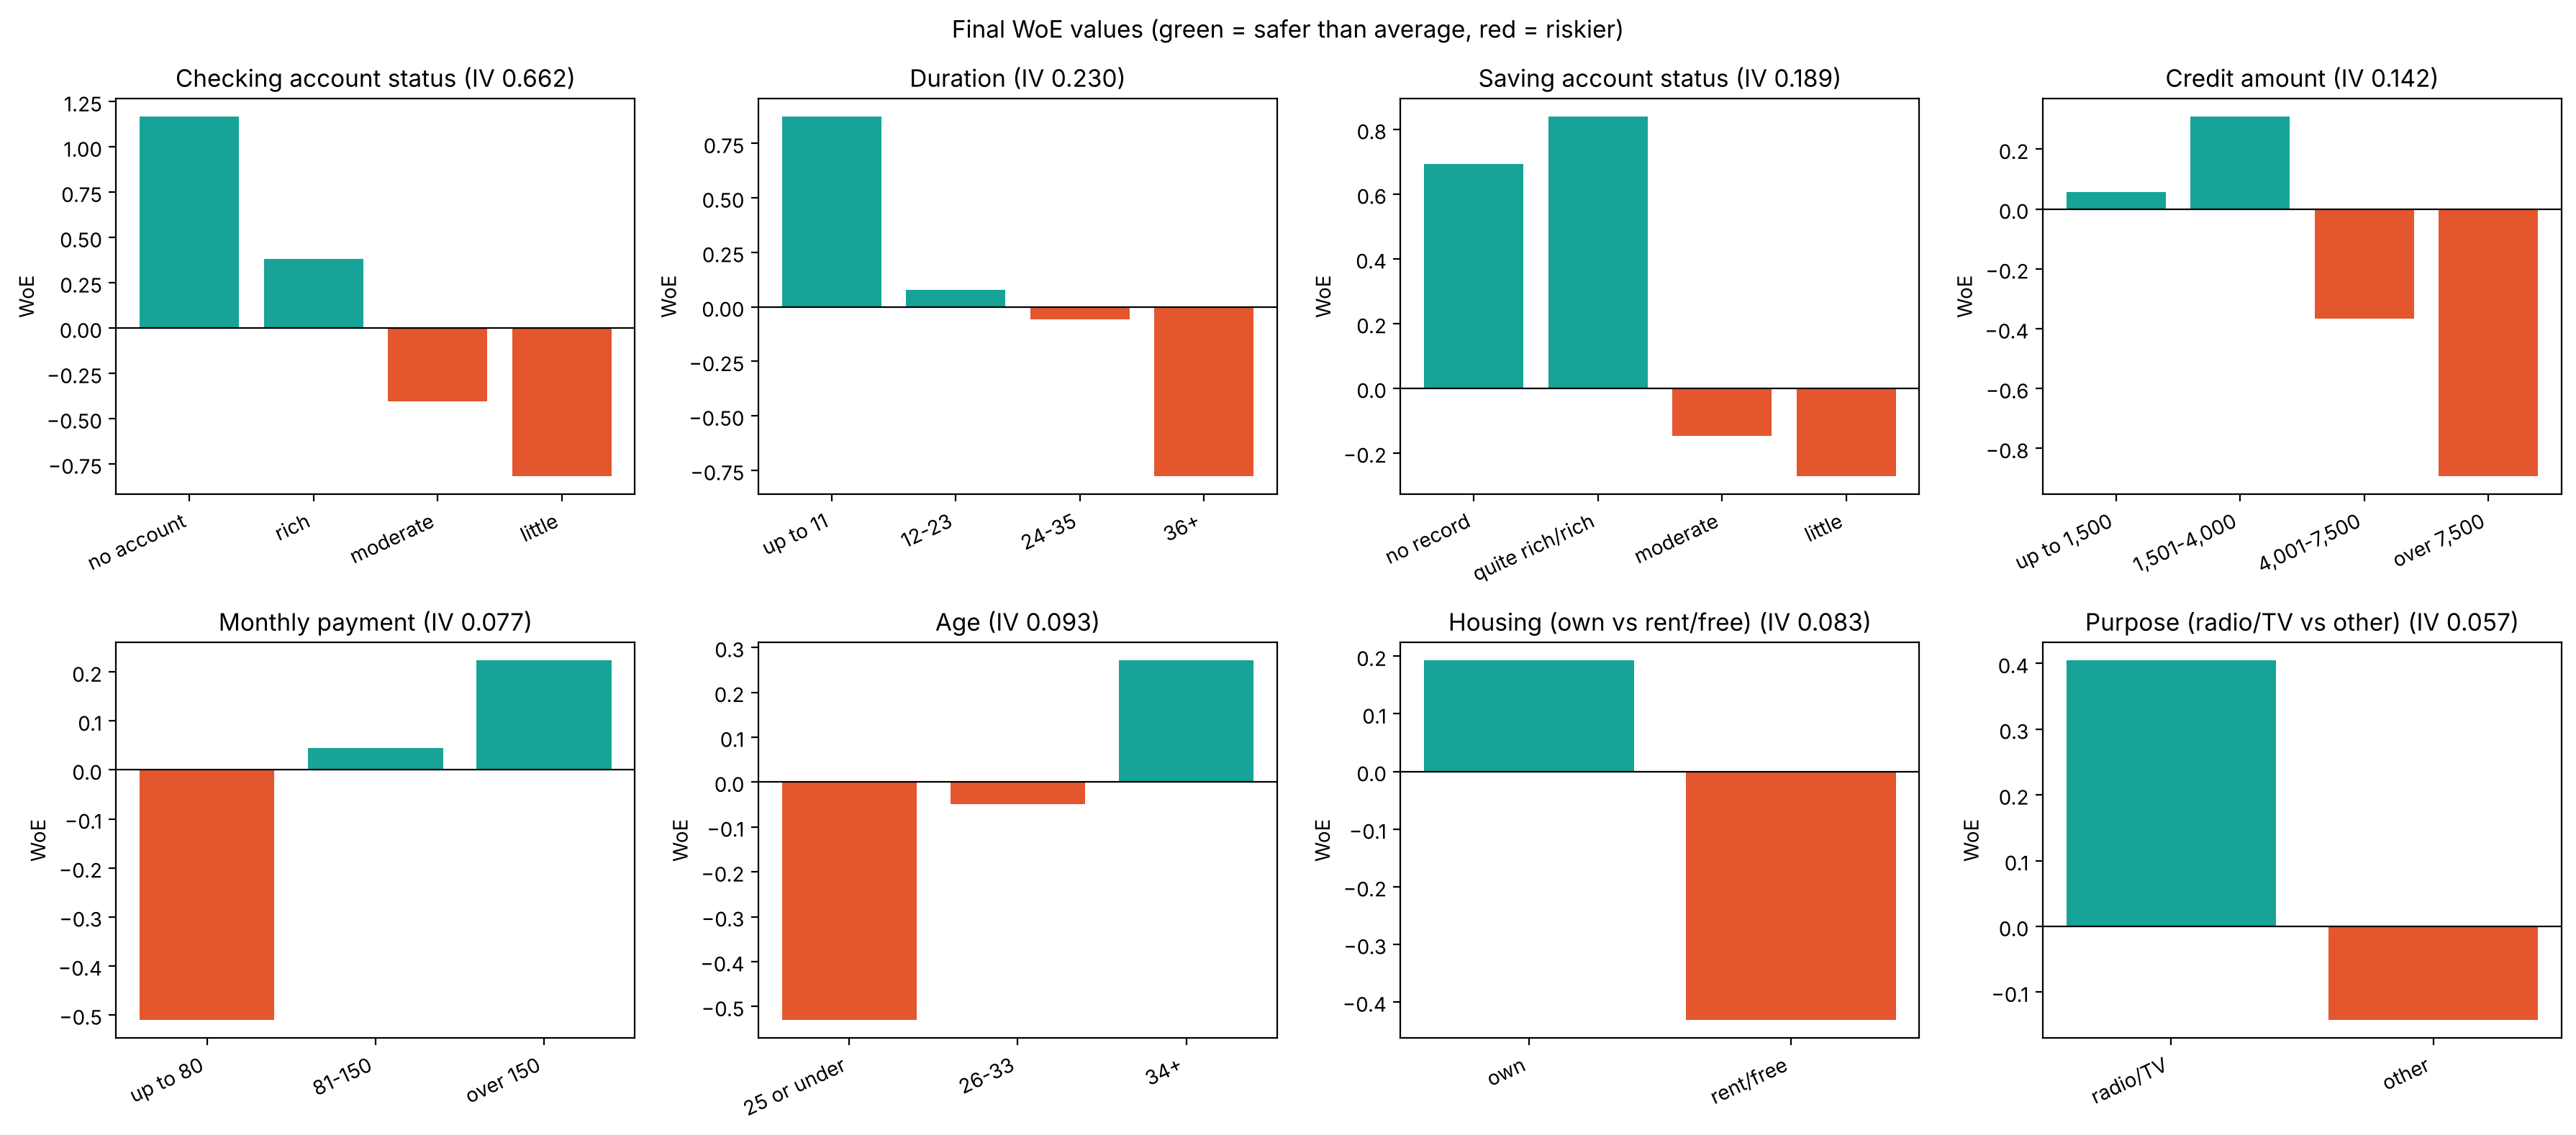

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
plot_order = {**order, 'home_owner': ['own', 'rent/free'], 'purpose_type': ['radio/TV', 'other']}
for ax, f in zip(axes.flatten(), final):
    s = woe_steps(fe, f).loc[plot_order[f]]
    ax.bar(s.index, s['WoE'], color=['#17A398' if w > 0 else '#E4572E' for w in s['WoE']])
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_title(f'{names[f]} (IV {s["IV part"].sum():.3f})')
    ax.set_ylabel('WoE')
    plt.setp(ax.get_xticklabels(), rotation=25, ha='right')
plt.suptitle('Final WoE values (green = safer than average, red = riskier)')
plt.tight_layout()
plt.show()

### C2. Save the final files

In [14]:
final_woe_table = pd.concat([woe_steps(fe, f).loc[plot_order[f]].assign(Feature=f).rename_axis('Band').reset_index() for f in final])
final_woe_table['Bad rate (%)'] = (final_woe_table['Bad'] / final_woe_table['Customers'] * 100).round(1)
final_woe_table = final_woe_table[['Feature', 'Band', 'Customers', 'Good', 'Bad', 'Bad rate (%)', 'WoE', 'IV part']].round(4)
final_woe_table.to_csv('data/processed/final_woe_iv_table.csv', index=False)

final_dataset = pd.DataFrame({'woe_' + f: fe[f].map(woe_map(fe, f).round(4)) for f in final})
final_dataset['bad'] = fe['bad']
final_dataset.to_csv('data/processed/german_credit_woe_final.csv', index=False)

final_table.assign(**{'WoE column': ['woe_' + f for f in final]}).to_csv('data/processed/final_features_submission.csv', index=False)

for path in ['data/processed/final_woe_iv_table.csv', 'data/processed/german_credit_woe_final.csv', 'data/processed/final_features_submission.csv']:
    print(path, pd.read_csv(path).shape)

data/processed/final_woe_iv_table.csv (26, 8)
data/processed/german_credit_woe_final.csv (1000, 9)
data/processed/final_features_submission.csv (8, 9)


## Quick checks

In [15]:
checks = {
    'Engineered features rebuild exactly from the raw data': rebuild_check['Identical to saved file'].all(),
    'Recalculated WoE and IV match the saved table for all 11 features': (recalc['Match'] == 'Yes').all(),
    '% good and % bad each add up to 1 for every feature': ((properties['Sum % good'] - 1).abs() < 1e-9).all() and ((properties['Sum % bad'] - 1).abs() < 1e-9).all(),
    'Every IV part is zero or positive': properties['IV parts >= 0'].all(),
    'WoE sign matches the bad rate in every band': properties['WoE sign matches bad rate'].all(),
    'WoE order is the exact reverse of bad-rate order': (properties['Rank correlation (bad rate, WoE)'] == -1).all(),
    'The 0.5 safeguard changes WoE by less than 0.05': (properties['Largest effect of 0.5 safeguard'] < 0.05).all(),
    'Saved WoE dataset matches the WoE tables': (woe_dataset_check['Match'] == 'Yes').all(),
    'Refined set beats the previous set on mean hold-out ROC-AUC': refinement.loc[1, 'Change vs previous'] > 0,
    'All 8 final features significant (p < 0.05) with negative coefficients': (final_table['p-value'] < 0.05).all() and (final_table['Coefficient'] < 0).all(),
    'All final VIF values below 5': (final_table['VIF'] < 5).all(),
    'Final WoE dataset has 1,000 rows and no missing values': len(final_dataset) == 1000 and final_dataset.isna().sum().sum() == 0,
}
for name, passed in checks.items():
    print('PASS' if passed else 'FAIL', '-', name)
assert all(checks.values())
print()
print(f'All {len(checks)} checks passed')

PASS - Engineered features rebuild exactly from the raw data
PASS - Recalculated WoE and IV match the saved table for all 11 features
PASS - % good and % bad each add up to 1 for every feature
PASS - Every IV part is zero or positive
PASS - WoE sign matches the bad rate in every band
PASS - WoE order is the exact reverse of bad-rate order
PASS - The 0.5 safeguard changes WoE by less than 0.05
PASS - Saved WoE dataset matches the WoE tables
PASS - Refined set beats the previous set on mean hold-out ROC-AUC
PASS - All 8 final features significant (p < 0.05) with negative coefficients
PASS - All final VIF values below 5
PASS - Final WoE dataset has 1,000 rows and no missing values

All 12 checks passed


## Conclusion

- **The WoE / IV calculations are correct.** The engineered features rebuild exactly from the raw data, every WoE and IV matches an
  independent step-by-step recalculation, and all mathematical properties hold.
- **The interpretations were reviewed.** Checking account, age, housing and job group are confirmed. Duration, savings, monthly payment and
  purpose are confirmed in direction but work as thresholds rather than smooth trends. The U-shape for credit amount is **not** supported:
  risk is flat up to 4,000 DM and then rises. The higher risk for women is not significant once age is allowed for.
- **Final selection: 8 features**, with Housing simplified to *own vs rent/free* and Purpose to *radio/TV vs other*.
  This removes the instability found earlier and slightly improves hold-out performance.
- Final files: `final_features_submission.csv`, `german_credit_woe_final.csv` and `final_woe_iv_table.csv` in `data/processed/`.